## Lab #2

Katherine Merrill

10-14-2026

Phys 434 AC

# Problem 1
### A) Show how the probability distribution of the background changes as you integrate (sum) for more days

For the pdf of a Poisson distribution, $P(k)=e^{-X}X^k/k!$, $\lambda$ = the average cosmic ray background X=2.3, and for the expected signal of source and background, $\lambda =X+Y=2.3+4=6.3 $ : 



The pdf of the sum of two independent counts is the convolution of their pdfs, $P_{A+B}(x)=\sum_j P_A(x)\,P_B(x-z)$. So convolving the one-day pdf with itself gives the 2-day pdf, convolving that with the one-day pdf gives the 3-day pdf, up to 5 days. 

Plot of each of the convolved sums over 5 days:

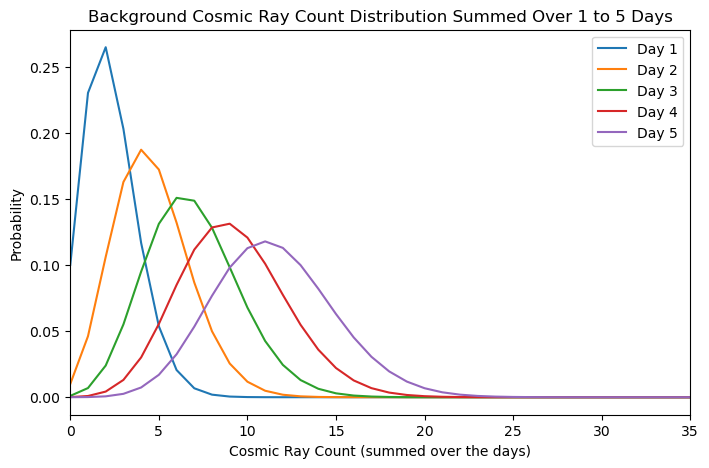

In [59]:
import numpy as np
import matplotlib.pyplot as plt
import scipy.stats as stats

X = 2.3  
Y = 4.0 

nk = 60
k = np.arange(0, nk)
day1 = stats.poisson.pmf(k, X)

day2 = np.convolve(day1, day1)[:nk]
day3 = np.convolve(day2, day1)[:nk]
day4 = np.convolve(day3, day1)[:nk]
day5 = np.convolve(day4, day1)[:nk]

plt.figure(figsize=(8, 5))
plt.plot(k, day1, label='Day 1')
plt.plot(k, day2, label='Day 2')
plt.plot(k, day3, label='Day 3')
plt.plot(k, day4, label='Day 4')
plt.plot(k, day5, label='Day 5')
plt.xlabel('Cosmic Ray Count (summed over the days)')
plt.ylabel('Probability')
plt.title('Background Cosmic Ray Count Distribution Summed Over 1 to 5 Days')
plt.xlim(0, 35)
plt.legend()
plt.show()

# B) Show that after 5 days, the summed probability distribution is still a Poisson distribution. Explain why this makes sense from a mathematical and conceptual point of view.

max diff=2.0816681711721685e-16


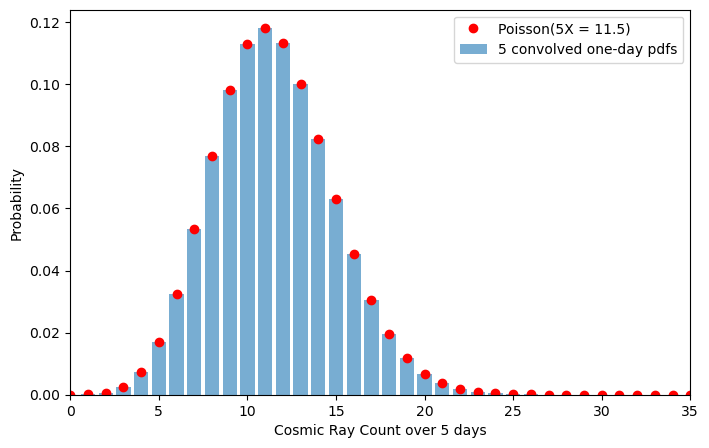

In [60]:
theoretical_day5 = stats.poisson.pmf(k, 5 * X)

max_diff = np.max(np.abs(day5 - theoretical_day5))
print(f"max diff={max_diff}")

plt.figure(figsize=(8, 5))
plt.bar(k, day5, alpha=0.6, label='5 convolved one-day pdfs')
plt.plot(k, theoretical_day5, 'ro', label='Poisson(5X = 11.5)')
plt.xlim(0, 35)
plt.xlabel('Cosmic Ray Count over 5 days')
plt.ylabel('Probability')
plt.legend()
plt.show()

The summed probability distribution (`day5`) differs from the theoretical Poisson pdf (`theoretical_day5`) by only 2.0816681711721685e-16. This is floating-point error and basically 0, so the 5-day sum is the same Poisson distribution with a larger mean.

This makes sense mathematically because the cosmic ray count for each day $X_i$ is Poisson with the same rate (2.3 events per day). The sum $\sum X_i$ is the total cosmic ray count accumulated over 5 days, and the new rate is $\sum \lambda_i = 11.5$. You can also see this from the generating function since the pgf of a Poisson is $e^{\lambda(z-1)}$, a convolution becomes a product of pgfs, and the product of $e^{\lambda_i(z-1)}$ is $e^{(\sum\lambda_i)(z-1)}$, which is again a Poisson pgf.

Conceptually this also makes sense since the events are independent and happen at a constant average rate, so a 5-day window is just a window 5 times as long. Counting in a 5-day interval is the same physical process as counting in a 1-day interval, with 5 times the expected counts.

I think the Sums of Poisson-Distributed Random Variables section of the Poisson Distribution Wikipedia page put it a bit more eloquently, where summing is the same as convolving:
"*If $X_i \sim \operatorname{Pois}(\lambda_i)$ for $i=1, \dots, n$ are independent, then:*

$$\sum_{i=1}^{n}X_i \sim \operatorname{Pois}\left(\sum_{i=1}^{n}\lambda_i\right)$$

*A converse is **Raikov's theorem**, which states that if the sum of two independent random variables is Poisson-distributed, then so is each of those two individual independent random variables.*"

[Wikipedia Page](https://en.wikipedia.org/wiki/Poisson_distribution)

## C) Show how the probability distribution evolves as you average days. Calculate for many different ranges of days, and explore the shape of the distribution as the number of days becomes larger. Discuss this in relation to both B) and the central limit theoem.

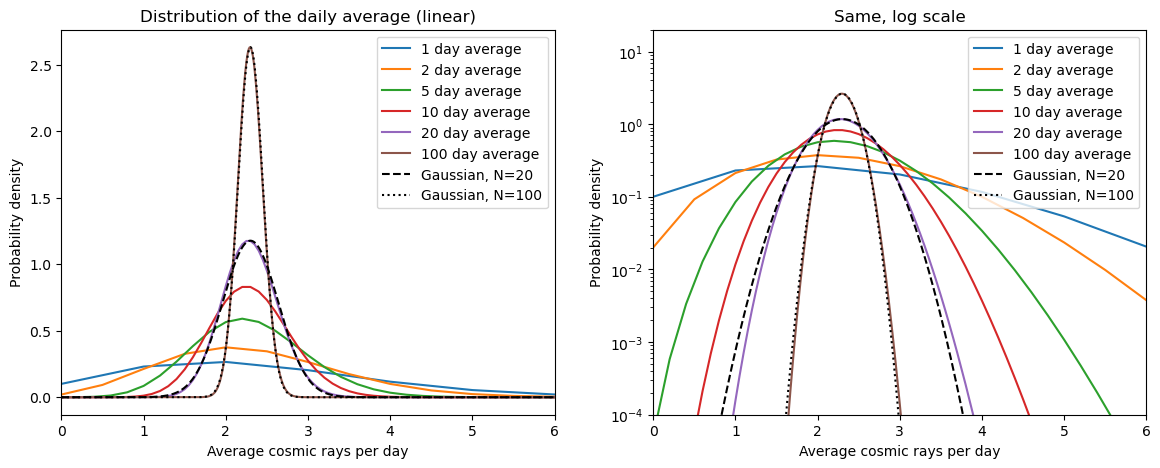

N   mean   std     sqrt(X/N)   skewness   1/sqrt(N*X)
1 2.3 1.5166 1.5166 0.6594 0.6594
2 2.3 1.0724 1.0724 0.4663 0.4663
5 2.3 0.6782 0.6782 0.2949 0.2949
10 2.3 0.4796 0.4796 0.2085 0.2085
20 2.3 0.3391 0.3391 0.1474 0.1474
100 2.3 0.1517 0.1517 0.0659 0.0659


In [61]:
days_to_check = [1, 2, 5, 10, 20, 100]
x_gauss = np.linspace(0, 6, 1000)

plt.figure(figsize=(14, 5))
for panel in [1, 2]:
    plt.subplot(1, 2, panel)
    for N in days_to_check:
        k_sum = np.arange(0, int(N * X * 3) + 10)
        p_sum = stats.poisson.pmf(k_sum, N * X) 
        k_avg = k_sum / N                         
        density = p_sum * N                    
        plt.plot(k_avg, density, label=str(N) + ' day average')

    plt.plot(x_gauss, stats.norm.pdf(x_gauss, X, np.sqrt(X / 20)), 'k--', label='Gaussian, N=20')
    plt.plot(x_gauss, stats.norm.pdf(x_gauss, X, np.sqrt(X / 100)), 'k:', label='Gaussian, N=100')

    plt.xlim(0, 6)
    plt.xlabel('Average cosmic rays per day')
    plt.ylabel('Probability density')
    plt.legend()
    if panel == 1:
        plt.title('Distribution of the daily average (linear)')
    else:
        plt.title('Same, log scale')
        plt.yscale('log')
        plt.ylim(1e-4, 20)
plt.show()

print("N   mean   std     sqrt(X/N)   skewness   1/sqrt(N*X)")
for N in days_to_check:
    k_sum = np.arange(0, int(N * X * 3) + 10)
    p_sum = stats.poisson.pmf(k_sum, N * X)
    k_avg = k_sum / N
    mean = np.sum(k_avg * p_sum)
    std = np.sqrt(np.sum((k_avg - mean)**2 * p_sum))
    skew = np.sum(((k_avg - mean) / std)**3 * p_sum)
    print(N, round(mean, 3), round(std, 4), round(np.sqrt(X / N), 4), round(skew, 4), round(1 / np.sqrt(N * X), 4))


As I average over $N$ days, the distribution gets narrower and more symmetric, and begins to look more like a Gaussian as I increase the number of days. I plotted it as a probability density so the average takes values in steps of $1/N$, so the density is the pmf divided by $1/N$.
This relates to part B because the probabilities of getting a certain average are the same as those of the corresponding sum, so both are determined by the same Poisson distribution. 

For the central limit theorem: the average of many independent identically distributed variables approaches a Gaussian with the same mean and $\sigma/\sqrt{N}$, and a Poisson with a large mean is well approximated by a Gaussian. The log plot shows that the convergence is slower in the tails, where the Poisson is still skewed.

### D) Pick some number of days N, and assume you saw Y*N gamma rays from your source. Calculate the 'sigma' of your observation.

For N=30 days and Y*N=120 gamma rays from source.

In [62]:
N = 30
observed = Y * N       
background = X * N    

p = stats.poisson.sf(observed - 1, background)  
sigma = stats.norm.isf(p)                    

print(f"background={background}, sigma ={sigma}")

background=69.0, sigma =5.519207458983384


For $N=30$ days I see 120 counts where the background expects 69, which has a significance of 5.5$\sigma$.

# Problem 2

My background is a Rayleigh distribution, $f(x)=\frac{x}{s^2}e^{-x^2/2s^2}$ with $s=1$ 

### A) Show how the distribution changes as you average over more observing intervals.

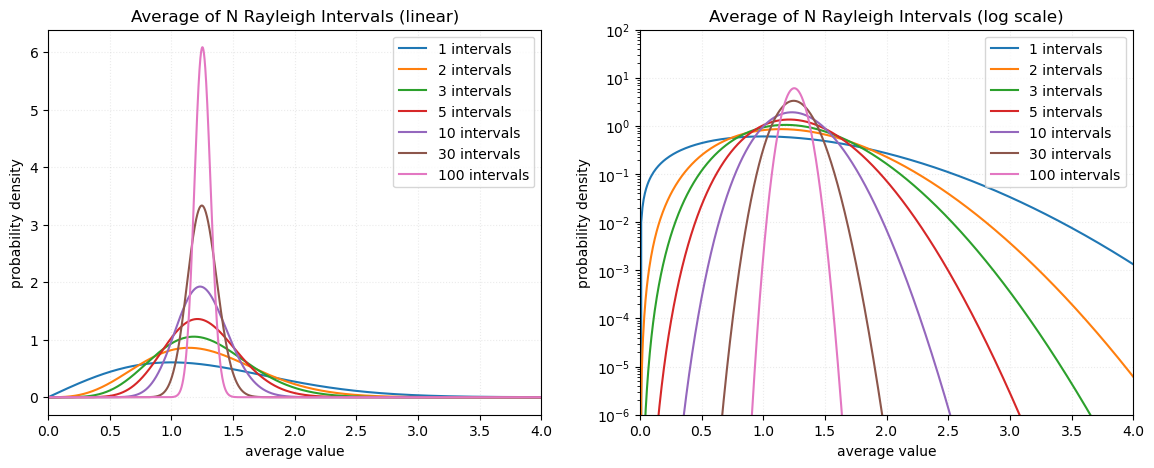

In [63]:
dx = 0.01
x = np.arange(0, 8, dx)             
pdf1 = stats.rayleigh.pdf(x) * dx  
pdf1 = pdf1 / np.sum(pdf1)        

mu1 = stats.rayleigh.mean()
sd1 = stats.rayleigh.std()

Ns = [1, 2, 3, 5, 10, 30, 100]

plt.figure(figsize=(14, 5))
for N in Ns:
    p = pdf1
    for i in range(N - 1):
        p = np.convolve(p, pdf1)         
    x_avg = np.arange(len(p)) * dx / N   
    density = p / (dx / N)              

    plt.subplot(1, 2, 1)
    plt.plot(x_avg, density, label=str(N) + ' intervals')
    plt.subplot(1, 2, 2)
    plt.plot(x_avg, density, label=str(N) + ' intervals')

plt.subplot(1, 2, 1)
plt.title('Average of N Rayleigh Intervals (linear)')
plt.xlabel('average value')
plt.ylabel('probability density')
plt.xlim(0, 4)
plt.grid(True, linestyle=':', alpha=0.25)
plt.legend()

plt.subplot(1, 2, 2)
plt.title('Average of N Rayleigh Intervals (log scale)')
plt.xlabel('average value')
plt.ylabel('probability density')
plt.xlim(0, 4)
plt.yscale('log')
plt.ylim(1e-6, 100)
plt.grid(True, linestyle=':', alpha=0.25)
plt.legend()
plt.show()

In the linear plot, the distribution gets narrower and taller as N increases, and its peak moves toward the mean of 1.25. For a single interval the peak is at 1, below the mean, with a long tail to the right. By N = 30–100 the curve is narrow and almost symmetric. 

The log plot shows the tails. The left tail (small averages) falls off much faster than the right, so the shape stays asymmetric out in the tails even when the core looks symmetric. 

### B) Discuss how the shape changes. Does it approach a Gaussian distribution? If yes, after how many intervals?


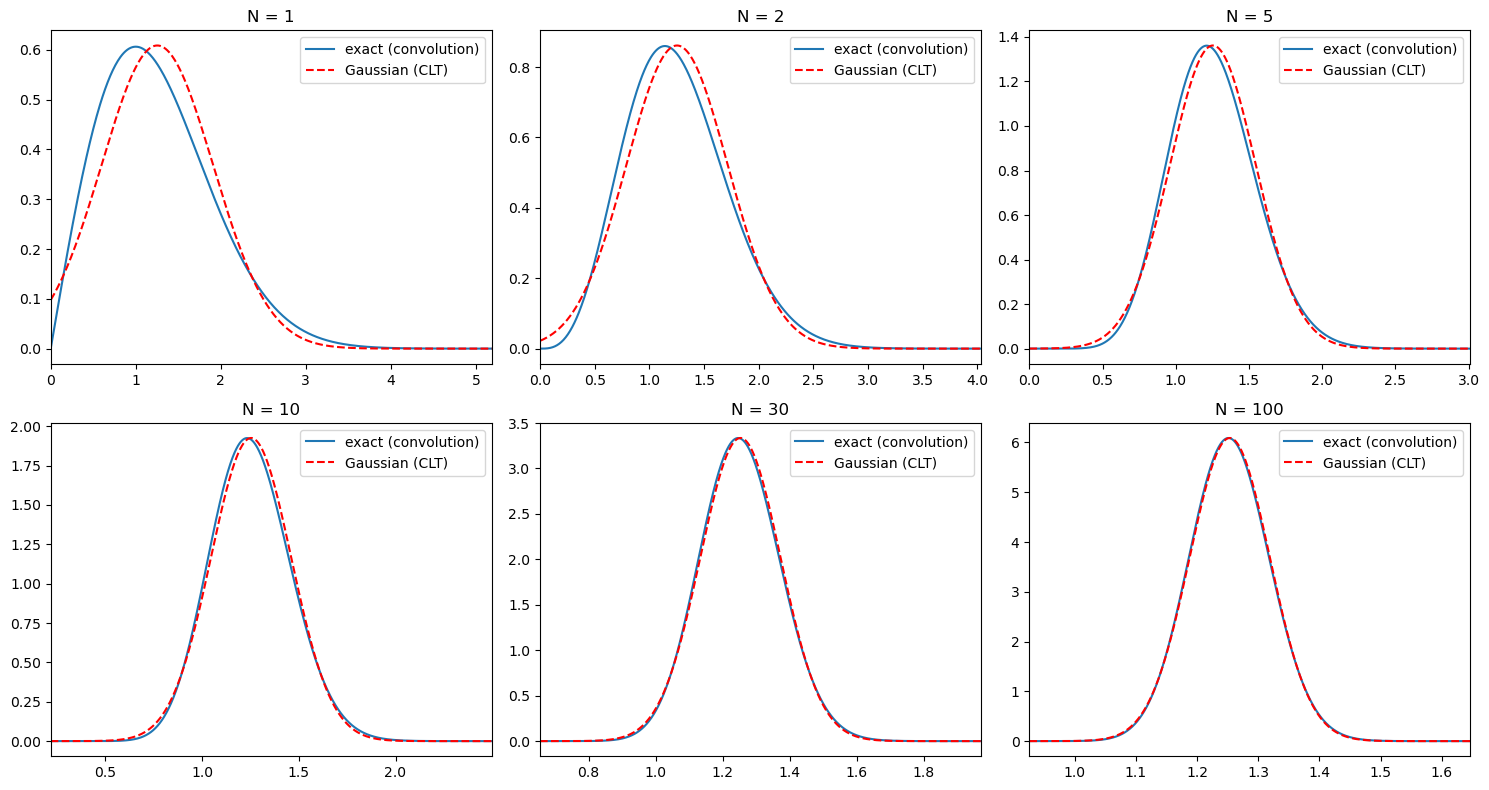

In [64]:
Ns_b = [1, 2, 5, 10, 30, 100]

plt.figure(figsize=(15, 8))
for j in range(len(Ns_b)):
    N = Ns_b[j]

    p = pdf1
    for i in range(N - 1):
        p = np.convolve(p, pdf1)
    x_avg = np.arange(len(p)) * dx / N
    density = p / (dx / N)

    sd_N = sd1 / np.sqrt(N)                      
    gauss = stats.norm.pdf(x_avg, mu1, sd_N)   
    plt.subplot(2, 3, j + 1)
    plt.plot(x_avg, density, label='exact (convolution)')
    plt.plot(x_avg, gauss, 'r--', label='Gaussian (CLT)')
    plt.xlim(max(0, mu1 - 5 * sd_N), mu1 + 6 * sd_N)
    plt.title('N = ' + str(N))
    plt.legend()
plt.tight_layout()
plt.show()

For a single interval (N = 1) the Rayleigh distribution is   not Gaussian since its lopsided and its peak is at 1 (below the mean of 1.25) and it has a long tail to the right. At N = 2 and N = 5 the exact curve is still visibly skewed compared to the red Gaussian, with its peak slightly to the left and a heavier right side, but by N = 30 I can’t tell them apart. So yes, the average of Rayleigh intervals approaches a Gaussian, which makes sense from the central limit theorem.

# Problem 3
My CCD background is a zero-mean Gaussian with width $\sigma_{bg}=1.5$ (in the flat-fielded brightness units). The signal I see is $Y=8.0$ in the same units.

## Version 1: I know which pixel
### A) Significance of the detection

In [65]:
sigma_bg = 1.5     
Y_sig = 8.0      
N_pix = 10000

p1 = stats.norm.sf(Y_sig, loc=0, scale=sigma_bg)
n_sigma_1 = stats.norm.isf(p1)

print("Y/sigma_bg =", Y_sig / sigma_bg)
print("p(background >= Y) =", p1)
print("significance =", round(n_sigma_1, 3), "sigma")

Y/sigma_bg = 5.333333333333333
p(background >= Y) = 4.821303365114125e-08
significance = 5.333 sigma


Probability that the background in this one pixel is as bright as or brighter than $Y$:

$p_1=\int_Y^\infty \mathcal{N}(x;0,\sigma_{bg})\,dx=\texttt{norm.sf}(Y/\sigma_{bg})=4.8\times10^{-8}$, which corresponds to $Y/\sigma_{bg}=5.33\sigma$. Since this is above $5\sigma$, yes,  I can claim a discovery

## Version 2:
### B) Probability distribution of the background if I have to look in 10k pixels

Statistical question:What is the pdf of the maximum of 10,000 background pixels?

In math: Let $f(x)$ and $F(x)$ be the single-pixel Gaussian pdf and cdf, and $p(x)=1-F(x)$ the single-pixel tail probability:

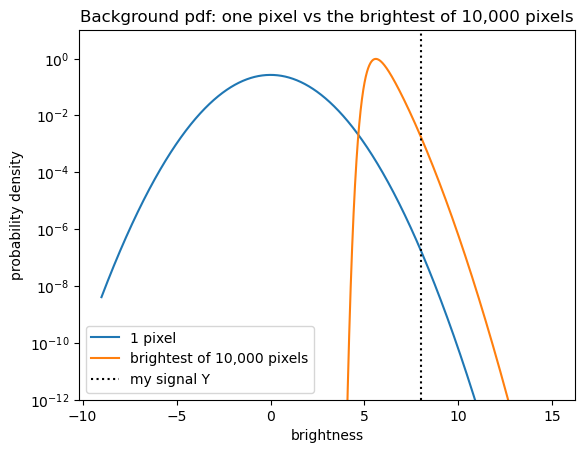

In [66]:
x = np.linspace(-9, 15, 4000)

f1 = stats.norm.pdf(x, 0, sigma_bg)      # pdf of one pixel
F1 = stats.norm.cdf(x, 0, sigma_bg)      # cdf of one pixel
fmax = N_pix * f1 * F1**(N_pix - 1)      # pdf of  brightest of 10,000 pixels

plt.plot(x, f1, label='1 pixel')
plt.plot(x, fmax, label='brightest of 10,000 pixels')
plt.axvline(Y_sig, color='k', linestyle=':', label='my signal Y')
plt.yscale('log')
plt.ylim(1e-12, 10)
plt.xlabel('brightness')
plt.ylabel('probability density')
plt.title('Background pdf: one pixel vs the brightest of 10,000 pixels')
plt.legend()
plt.show()

## C) Taking your brightest candidate signal from the region (assume it has the same signal as in part 1), calculate the significance of your detection.

In [67]:
p_trials_exact = 1 - (1 - p1)**N_pix       
p_trials_approx = N_pix * p1               

n_sigma_2_exact = stats.norm.isf(p_trials_exact)
n_sigma_2_approx = stats.norm.isf(N_pix * p1)

print("Version 2: p =", p_trials_exact, "(exact),", p_trials_approx, "(N*p)")
print("           ->", round(n_sigma_2_exact, 3), "sigma (exact),", round(n_sigma_2_approx, 3), "sigma (N*p)")

Version 2: p = 0.00048201414222759364 (exact), 0.0004821303365114125 (N*p)
           -> 3.301 sigma (exact), 3.301 sigma (N*p)


It's less than 5 sigma, so its not a significant detection.

## Problem 4

## Part A

$5\sigma$ corresponds to the probability $p_5=\texttt{norm.sf}(5)=2.87\times10^{-7}$, so the signal needed is $Y_{5}=\texttt{isf}(p_5)\,\sigma_{bg}=5\sigma_{bg}$.


### B) Version 2
Now the *brightest-pixel* probability must be $p_5$: $1-(1-p_{loc})^N=p_5$, so $p_{loc}=1-(1-p_5)^{1/N}\approx p_5/N$,so the signal needed is $Y=\texttt{isf}(p_{loc})\,\sigma_{bg}$.

### C) Discuss how much brighter the signal must be for discoverey if you have a trials factor of 10k. Looking at your probability distributions, explain why the sensitivity penalty due to a trials factor is so low.

The signal must go from $5.00\sigma_{bg}$ ($Y=7.5$) to $6.55\sigma_{bg}$ ($Y=9.83$), only about 31% brighter, even though I'm looking 10,000 times as often.

In the plot below, the trials factor shifts the tail up by 4 decades (a vertical shift), but the tail is so steep that this corresponds to only a small horizontal shift in $x$. 

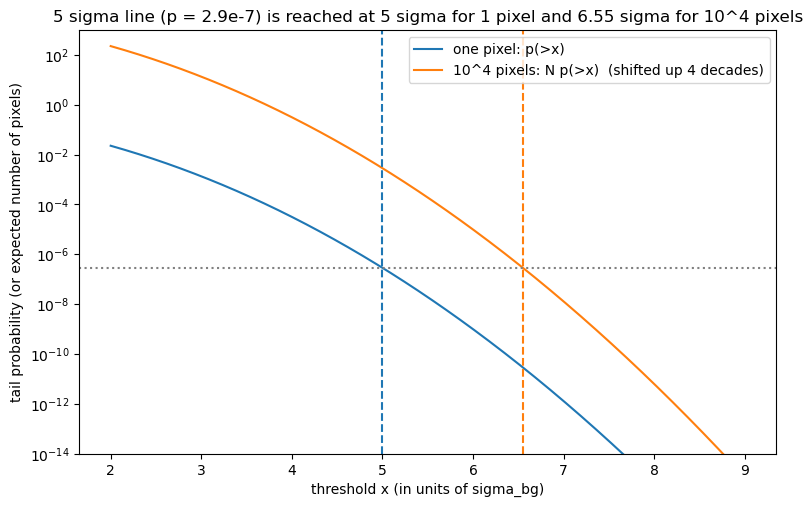

In [68]:
xs = np.linspace(2, 9, 500)
sf_x = stats.norm.sf(xs)
p5 = stats.norm.sf(5)
p_loc_exact = 1 - (1 - p5)**(1 / N_pix)
Y5_v2 = stats.norm.isf(p_loc_exact) * sigma_bg


plt.figure(figsize=(9, 5.5))
plt.semilogy(xs, sf_x, label='one pixel: p(>x)')
plt.semilogy(xs, N_pix * sf_x, label='10^4 pixels: N p(>x)  (shifted up 4 decades)')
plt.axhline(p5, color='gray', linestyle=':')
plt.axvline(5, color='C0', linestyle='--')
plt.axvline(Y5_v2 / sigma_bg, color='C1', linestyle='--')
plt.title('5 sigma line (p = 2.9e-7) is reached at 5 sigma for 1 pixel and ' + str(round(Y5_v2 / sigma_bg, 2)) + ' sigma for 10^4 pixels')
plt.xlabel('threshold x (in units of sigma_bg)')
plt.ylabel('tail probability (or expected number of pixels)')
plt.ylim(1e-14, 1e3)
plt.legend()
plt.show()

## D) If I changed the trials factor by orders of magnitude, how large is the effect on the 5σ threshold?


For each trials factor N, I divided the 5σ probability by N. I then converted this probability back into a number of σ with isf. 

In [69]:
p5 = stats.norm.sf(5)    

print("trials   sigma needed   ratio to 5 sigma")
for power in range(0, 21, 2):
    N = 10**power
    sigma_needed = stats.norm.isf(p5 / N)
    print("1e" + str(power), round(sigma_needed, 2), round(sigma_needed / 5, 2))

trials   sigma needed   ratio to 5 sigma
1e0 5.0 1.0
1e2 5.82 1.16
1e4 6.55 1.31
1e6 7.21 1.44
1e8 7.81 1.56
1e10 8.37 1.67
1e12 8.9 1.78
1e14 9.39 1.88
1e16 9.87 1.97
1e18 10.32 2.06
1e20 10.75 2.15
